# Практическая работа 5.1. Подготовка датасета


## Импорты


In [1]:
from __future__ import annotations

import os
import random
import shutil
from pathlib import Path

PRACTICE_DIR = Path.cwd()
CACHE_DIR = PRACTICE_DIR / ".cache"
DATA_DIR = PRACTICE_DIR / ".data"
MPL_CACHE_DIR = CACHE_DIR / "matplotlib"
IPYTHON_CACHE_DIR = CACHE_DIR / "ipython"
XDG_CACHE_DIR = CACHE_DIR / "xdg"
SOURCE_DATASET_DIR = DATA_DIR / "wonders-of-world-source"
PREPARED_DATASET_DIR = DATA_DIR / "wonders-of-world-prepared"

for directory in (CACHE_DIR, DATA_DIR, MPL_CACHE_DIR, IPYTHON_CACHE_DIR, XDG_CACHE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

os.environ["MPLCONFIGDIR"] = str(MPL_CACHE_DIR)
os.environ["IPYTHONDIR"] = str(IPYTHON_CACHE_DIR)
os.environ["XDG_CACHE_HOME"] = str(XDG_CACHE_DIR)
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"


In [2]:
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

SEED = 42
IMAGE_SIZE = 180
SPLIT_FRACTIONS = (0.70, 0.15, 0.15)

DATASET_HANDLE = "balabaskar/wonders-of-the-world-image-classification"
DATASET_ROOT = SOURCE_DATASET_DIR / "Wonders of World" / "Wonders of World"
SELECTED_CLASSES = [
    ("burj_khalifa", "burj_khalifa"),
    ("christ_the_reedemer", "christ_the_redeemer"),
    ("eiffel_tower", "eiffel_tower"),
    ("statue_of_liberty", "statue_of_liberty"),
    ("machu_pichu", "machu_picchu"),
    ("pyramids_of_giza", "pyramids_of_giza"),
    ("roman_colosseum", "roman_colosseum"),
]

random.seed(SEED)
np.random.seed(SEED)
plt.style.use("seaborn-v0_8-whitegrid")

if not np.isclose(sum(SPLIT_FRACTIONS), 1.0):
    raise ValueError("Сумма долей train, validation и test должна быть равна 1.")


/Users/mikhail/Developer/SUSU.PE/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Описание данных

В работе используется датасет `Wonders of the World Image Classification` с Kaggle. Из исходного набора выбираются `7` классов с уникальными архитектурными объектами, после чего данные приводятся к общему сбалансированному разбиению `train`, `validation` и `test`.


### Загрузка датасета


In [3]:
def download_dataset_if_needed(
    source_dataset_dir: Path,
    dataset_root: Path,
    dataset_handle: str,
) -> None:
    """
    Скачивает датасет Kaggle, если локальная копия еще не подготовлена.

    Parameters
    ----------
    source_dataset_dir : Path
        Каталог для скачивания датасета.
    dataset_root : Path
        Каталог с папками классов.
    dataset_handle : str
        Идентификатор датасета на Kaggle.
    """
    if dataset_root.is_dir():
        return

    kagglehub.dataset_download(
        dataset_handle,
        output_dir=str(source_dataset_dir),
    )


In [4]:
def collect_class_images(
    dataset_root: Path,
    selected_classes: list[tuple[str, str]],
) -> dict[str, list[Path]]:
    """
    Собирает пути к изображениям выбранных классов.

    Parameters
    ----------
    dataset_root : Path
        Каталог с папками исходных классов.
    selected_classes : list[tuple[str, str]]
        Пары из имени исходной папки и итогового имени класса.

    Returns
    -------
    dict[str, list[Path]]
        Словарь с изображениями по классам.
    """
    class_to_images: dict[str, list[Path]] = {}

    for source_class_name, target_class_name in selected_classes:
        class_directory = dataset_root / source_class_name

        if not class_directory.is_dir():
            raise FileNotFoundError(f"Папка класса {class_directory} не найдена.")

        image_paths = sorted(
            image_path
            for image_path in class_directory.iterdir()
            if image_path.is_file()
        )

        if not image_paths:
            raise FileNotFoundError(f"Для класса {target_class_name} не найдены изображения.")

        class_to_images[target_class_name] = image_paths

    return class_to_images


In [5]:
download_dataset_if_needed(
    SOURCE_DATASET_DIR,
    DATASET_ROOT,
    DATASET_HANDLE,
)

class_to_images = collect_class_images(
    DATASET_ROOT,
    SELECTED_CLASSES,
)

class_names = sorted(class_to_images)
class_counts = np.asarray(
    [len(class_to_images[class_name]) for class_name in class_names],
    dtype=np.int64,
)

print(f"Количество изображений: {int(class_counts.sum())}")
print(f"Количество классов: {len(class_names)}")
print("Классы:", class_names)


Количество изображений: 2501
Количество классов: 7
Классы: ['burj_khalifa', 'christ_the_redeemer', 'eiffel_tower', 'machu_picchu', 'pyramids_of_giza', 'roman_colosseum', 'statue_of_liberty']


## Обзор данных

Ниже показано количество изображений по выбранным классам и несколько примеров из исходного набора.


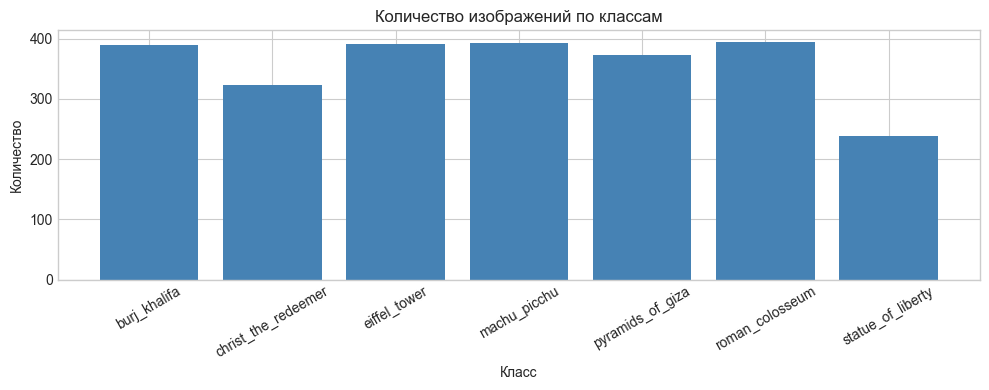

In [6]:
fig, axis = plt.subplots(figsize=(10, 4))
axis.bar(class_names, class_counts, color="steelblue")
axis.set_title("Количество изображений по классам")
axis.set_xlabel("Класс")
axis.set_ylabel("Количество")
axis.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()


In [7]:
def show_preview(
    class_to_images: dict[str, list[Path]],
    class_names: list[str],
    image_size: int,
    *,
    num_images: int = 12,
) -> None:
    """
    Показывает несколько исходных изображений из датасета.

    Parameters
    ----------
    class_to_images : dict[str, list[Path]]
        Изображения, сгруппированные по классам.
    class_names : list[str]
        Названия классов.
    image_size : int
        Размер изображения для превью.
    num_images : int
        Количество изображений в превью.
    """
    all_image_paths = [
        image_path
        for class_name in class_names
        for image_path in class_to_images[class_name]
    ]
    all_labels = [
        class_name
        for class_name in class_names
        for _ in class_to_images[class_name]
    ]

    preview_size = min(num_images, len(all_image_paths))
    preview_indices = random.sample(range(len(all_image_paths)), k=preview_size)

    fig, axes = plt.subplots(3, 4, figsize=(10, 8))
    axes = np.asarray(axes).reshape(-1)

    for axis, image_index in zip(axes, preview_indices):
        image = Image.open(all_image_paths[image_index]).convert("RGB")
        image = image.resize((image_size, image_size))
        axis.imshow(image)
        axis.set_title(all_labels[image_index], fontsize=9)
        axis.axis("off")

    for axis in axes[preview_size:]:
        axis.axis("off")

    plt.tight_layout()
    plt.show()


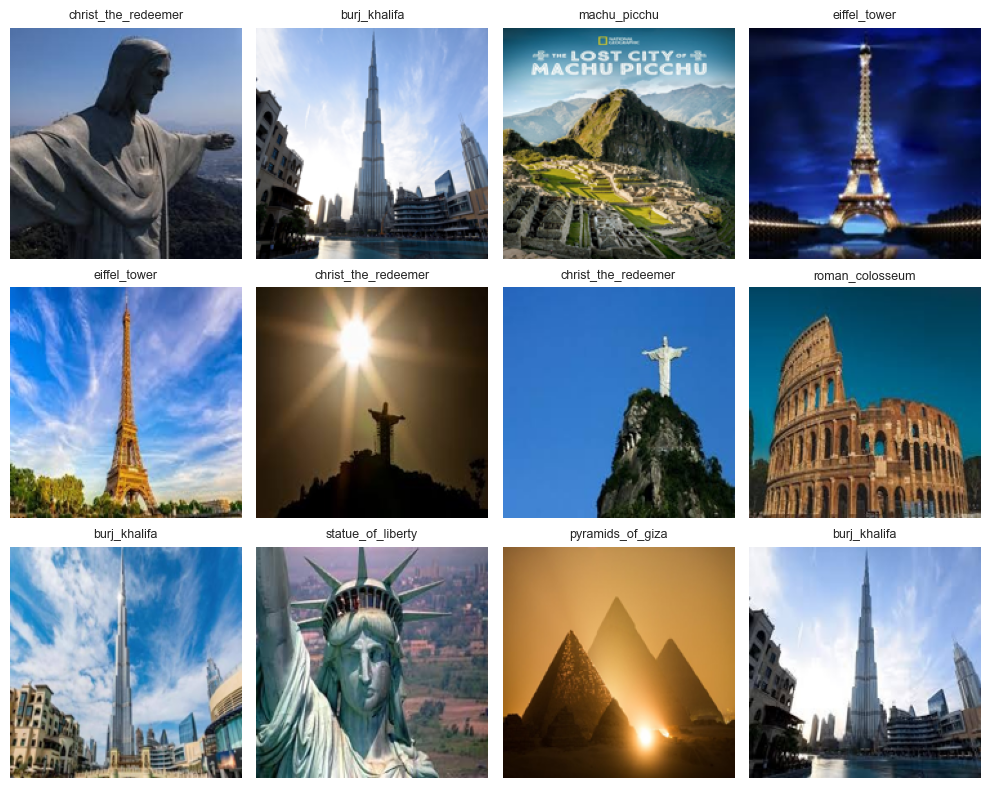

In [8]:
show_preview(
    class_to_images,
    class_names,
    IMAGE_SIZE,
)


## Подготовка данных

Здесь каждый класс ограничивается минимальным количеством изображений, после чего формируется новое сбалансированное разбиение `train`, `validation` и `test`.


In [9]:
def make_balanced_split(
    class_to_images: dict[str, list[Path]],
    split_fractions: tuple[float, float, float],
    seed: int,
) -> tuple[dict[str, dict[str, list[Path]]], int]:
    """
    Формирует новое сбалансированное разбиение по выбранным классам.

    Parameters
    ----------
    class_to_images : dict[str, list[Path]]
        Изображения, сгруппированные по классам.
    split_fractions : tuple[float, float, float]
        Доли train, validation и test.
    seed : int
        Начальное значение генератора случайных чисел.

    Returns
    -------
    tuple[dict[str, dict[str, list[Path]]], int]
        Разбиение по выборкам и минимальное число изображений в классе.
    """
    min_class_count = min(len(image_paths) for image_paths in class_to_images.values())
    train_fraction, validation_fraction, test_fraction = split_fractions

    validation_count = int(min_class_count * validation_fraction)
    test_count = int(min_class_count * test_fraction)
    train_count = min_class_count - validation_count - test_count

    split_to_images: dict[str, dict[str, list[Path]]] = {
        "train": {},
        "validation": {},
        "test": {},
    }

    for class_name, image_paths in class_to_images.items():
        shuffled_paths = image_paths.copy()
        random.Random(seed).shuffle(shuffled_paths)
        balanced_paths = shuffled_paths[:min_class_count]

        split_to_images["train"][class_name] = balanced_paths[:train_count]
        split_to_images["validation"][class_name] = balanced_paths[train_count:train_count + validation_count]
        split_to_images["test"][class_name] = balanced_paths[train_count + validation_count:]

    return split_to_images, min_class_count


In [10]:
split_to_images, min_class_count = make_balanced_split(
    class_to_images,
    SPLIT_FRACTIONS,
    SEED,
)

split_counts = {
    split_name: np.asarray(
        [len(split_to_images[split_name][class_name]) for class_name in class_names],
        dtype=np.int64,
    )
    for split_name in ("train", "validation", "test")
}

print(f"Минимальный размер класса: {min_class_count}")
for split_name, counts in split_counts.items():
    print(f"{split_name.capitalize()}: {int(counts.sum())}")
    for class_name, count in zip(class_names, counts):
        print(f"  {class_name}: {count}")


Минимальный размер класса: 238
Train: 1176
  burj_khalifa: 168
  christ_the_redeemer: 168
  eiffel_tower: 168
  machu_picchu: 168
  pyramids_of_giza: 168
  roman_colosseum: 168
  statue_of_liberty: 168
Validation: 245
  burj_khalifa: 35
  christ_the_redeemer: 35
  eiffel_tower: 35
  machu_picchu: 35
  pyramids_of_giza: 35
  roman_colosseum: 35
  statue_of_liberty: 35
Test: 245
  burj_khalifa: 35
  christ_the_redeemer: 35
  eiffel_tower: 35
  machu_picchu: 35
  pyramids_of_giza: 35
  roman_colosseum: 35
  statue_of_liberty: 35


## Распределение данных

Диаграммы показывают, что новое разбиение одинаково распределяет изображения между классами.


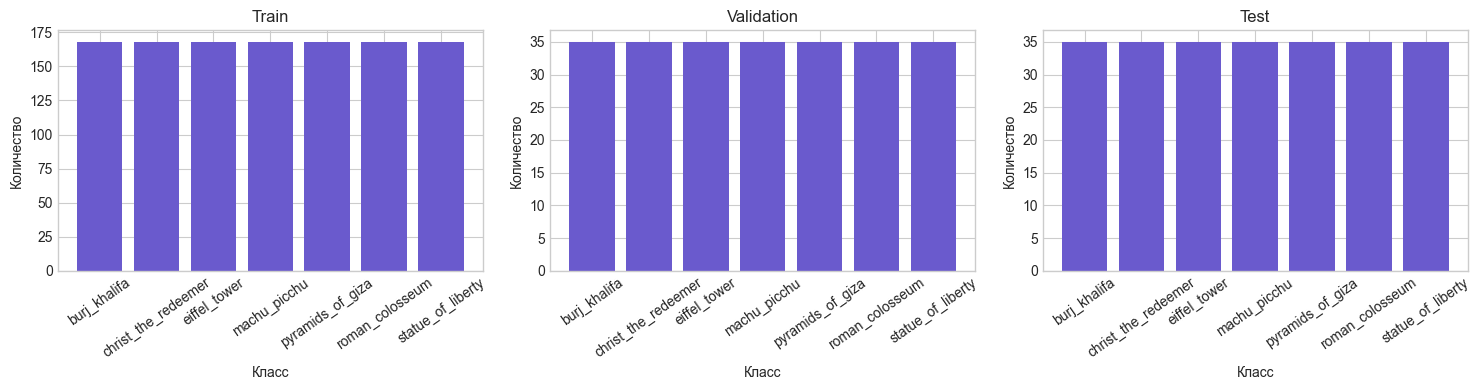

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for axis, split_name in zip(axes, ("train", "validation", "test")):
    counts = split_counts[split_name]
    axis.bar(class_names, counts, color="slateblue")
    axis.set_title(split_name.capitalize())
    axis.set_xlabel("Класс")
    axis.set_ylabel("Количество")
    axis.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()


## Сохранение подготовленного датасета

Последний шаг перепаковывает изображения в папки `train`, `validation` и `test`, которые дальше будут считываться из TensorFlow.


In [12]:
def reset_directory(directory: Path) -> None:
    """
    Полностью пересоздает каталог.

    Parameters
    ----------
    directory : Path
        Каталог для пересоздания.
    """
    if directory.exists():
        shutil.rmtree(directory)

    directory.mkdir(parents=True, exist_ok=True)


In [13]:
def create_prepared_dataset(
    prepared_dataset_dir: Path,
    split_to_images: dict[str, dict[str, list[Path]]],
) -> dict[str, int]:
    """
    Копирует изображения в итоговую структуру prepared датасета.

    Parameters
    ----------
    prepared_dataset_dir : Path
        Итоговый каталог prepared датасета.
    split_to_images : dict[str, dict[str, list[Path]]]
        Разбиение изображений по выборкам и классам.

    Returns
    -------
    dict[str, int]
        Количество изображений в каждой выборке.
    """
    reset_directory(prepared_dataset_dir)

    split_sizes: dict[str, int] = {}

    for split_name, class_mapping in split_to_images.items():
        split_total = 0

        for class_name, image_paths in class_mapping.items():
            class_directory = prepared_dataset_dir / split_name / class_name
            class_directory.mkdir(parents=True, exist_ok=True)

            for image_index, image_path in enumerate(image_paths, start=1):
                target_name = f"{class_name}_{image_index:04d}{image_path.suffix.lower()}"
                shutil.copy2(image_path, class_directory / target_name)

            split_total += len(image_paths)

        split_sizes[split_name] = split_total

    return split_sizes


In [14]:
prepared_split_sizes = create_prepared_dataset(
    PREPARED_DATASET_DIR,
    split_to_images,
)

print(f"Prepared dataset: {PREPARED_DATASET_DIR}")
for split_name, split_size in prepared_split_sizes.items():
    print(f"{split_name.capitalize()}: {split_size}")


Prepared dataset: /Users/mikhail/Developer/SUSU.PE/СП-М-О-КЗ-2025/Практика/Практика 5 - Основы работы в Keras/.data/wonders-of-world-prepared
Train: 1176
Validation: 245
Test: 245
